In [1]:
import pandas as pd
df = pd.read_csv('social_media_engagement_5000.csv')
print(df.shape)

(5000, 19)


In [2]:
import numpy as np

# Check data types
print("Data Types:\n", df.dtypes)

# Convert date columns to datetime if present
if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])

# Use NumPy arrays for basic array operations
likes_array = np.array(df['likes'])
print("\nNumPy - Total Likes:", np.sum(likes_array))
print("NumPy - Mean Likes:", np.mean(likes_array))

Data Types:
 user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

NumPy - Total Likes: nan
NumPy - Mean Likes: nan


In [6]:
import numpy as np

# 1. Handle Missing Data safely
numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(include=['object']).columns

for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()
        if not mode_val.empty:
            df[col] = df[col].fillna(mode_val[0])
        else:
            df[col] = df[col].fillna("Unknown")

# 2. Identify & remove duplicates[cite: 1]
df.drop_duplicates(inplace=True)

# 3. Standardize categories & correct unrealistic/negative values[cite: 1]
if 'gender' in df.columns:
    df['gender'] = df['gender'].astype(str).str.lower().str.strip()
    df['gender'] = df['gender'].replace({'m': 'male', 'f': 'female', 'nan': 'unknown'})

for col in ['likes', 'comments', 'shares']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
        df[col] = df[col].apply(lambda x: max(0, x))

# 4. Feature Cleaning (Extract hashtag count & sentiment)[cite: 1]
if 'caption' in df.columns:
    df['hashtag_count'] = df['caption'].astype(str).apply(lambda x: x.count('#'))

if 'sentiment' in df.columns:
    df['sentiment'] = df['sentiment'].astype(str).str.lower().str.strip()

print("Data cleaning completed successfully! Cleaned shape:", df.shape)

Data cleaning completed successfully! Cleaned shape: (5000, 19)


In [8]:
# View structure and info
print(df.head())
df.info()

# Summary statistics
print("\nSummary Statistics:\n", df.describe())

# Categorical distributions
for col in ['post_type', 'country', 'sentiment']:
    if col in df.columns:
        print(f"\nValue counts for {col}:\n", df[col].value_counts())

# Correlation matrix for numeric fields
numeric_df = df.select_dtypes(include=[np.number])
print("\nCorrelation Matrix:\n", numeric_df.corr())

# Groupby summaries
if 'post_type' in df.columns and 'likes' in df.columns:
    print("\nAvg Likes by Post Type:\n", df.groupby('post_type')['likes'].mean())

   user_id   age  gender country  post_id post_type post_category    likes  \
0    25795  43.0  female  Brazil   496713     image       fitness   7011.0   
1    10860  33.0    male  Brazil   157326      reel          food  11750.0   
2    86820  32.0  female      UK   109864      text          food   4862.0   
3    64886  51.0   other  France   848877      text       fitness   5350.0   
4    16265  34.0   other      UK   449706     image       fitness  12682.0   

   comments  shares  watch_time_sec  impression_count   posted_at  \
0     354.0  1157.0            5726             44650  17-12-2022   
1    2606.0  1807.0            5947             80216  02-06-2023   
2     344.0   955.0            6946             44858  07-05-2023   
3    1083.0  1049.0             229             70455  12-02-2023   
4    2735.0  1300.0            4798              6019  23-05-2023   

   follower_count  is_verified device_type sentiment               hashtags  \
0           81734        False      m

In [10]:
# 1. Safely create engagement score if the source columns exist
score_cols = ['likes', 'comments', 'shares']
if all(col in df.columns for col in score_cols):
    df['engagement_score'] = df['likes'] + (df['comments'] * 2) + (df['shares'] * 3)
    print("Created 'engagement_score' successfully.")
else:
    print("Skipped 'engagement_score': one or more columns (likes, comments, shares) missing.")

# 2. Log-transformed metrics (optional task check)
if 'impressions' in df.columns:
    df['log_impressions'] = np.log1p(df['impressions'])
    print("Created 'log_impressions' successfully.")

# 3. Dynamic Groupby Summaries based on available columns
group_keys = [col for col in ['post_type', 'country', 'sentiment'] if col in df.columns]
agg_dict = {}

if 'likes' in df.columns:
    agg_dict['likes'] = 'mean'
if 'engagement_score' in df.columns:
    agg_dict['engagement_score'] = 'mean'
if 'impressions' in df.columns:
    agg_dict['impressions'] = 'sum'

if group_keys and agg_dict:
    wrangled_summary = df.groupby(group_keys).agg(agg_dict).reset_index()
    print("\nWrangled Summary Preview:")
    display(wrangled_summary.head())
else:
    print("Could not generate groupby summary due to missing columns.")

Created 'engagement_score' successfully.

Wrangled Summary Preview:


,post_type,country,sentiment,likes,engagement_score
0,image,Australia,negative,7474.263158,12622.105263
1,image,Australia,neutral,9443.071429,16275.452381
2,image,Australia,positive,10081.590909,16300.515152
3,image,Brazil,negative,7559.350000,13888.300000
4,image,Brazil,neutral,7970.260870,14376.021739


In [11]:
stats_cols = ['likes', 'comments', 'shares', 'watch_time', 'engagement_rate', 'followers']
available_cols = [c for c in stats_cols if c in df.columns]

stats_summary = {}
for col in available_cols:
    stats_summary[col] = {
        'Mean': df[col].mean(),
        'Median': df[col].median(),
        'Mode': df[col].mode()[0],
        'Std Dev': df[col].std(),
        'Variance': df[col].var(),
        '25th Percentile': df[col].quantile(0.25),
        '75th Percentile': df[col].quantile(0.75),
        'Skewness': df[col].skew(),
        'Kurtosis': df[col].kurtosis()
    }

stats_df = pd.DataFrame(stats_summary)
print(stats_df)

                        likes       comments         shares  engagement_rate
Mean             9.803832e+03    1457.129800     972.550600         0.964356
Median           9.776000e+03    1454.500000     981.500000         0.253896
Mode             0.000000e+00       0.000000       0.000000         0.006363
Std Dev          5.957296e+03     893.917601     595.929688         5.318029
Variance         3.548937e+07  799088.677487  355132.192678        28.281435
25th Percentile  4.625750e+03     675.000000     447.750000         0.145781
75th Percentile  1.495900e+04    2235.250000    1483.000000         0.504794
Skewness         2.275244e-04       0.011841      -0.002932        18.781271
Kurtosis        -1.213896e+00      -1.210470      -1.215102       482.991739


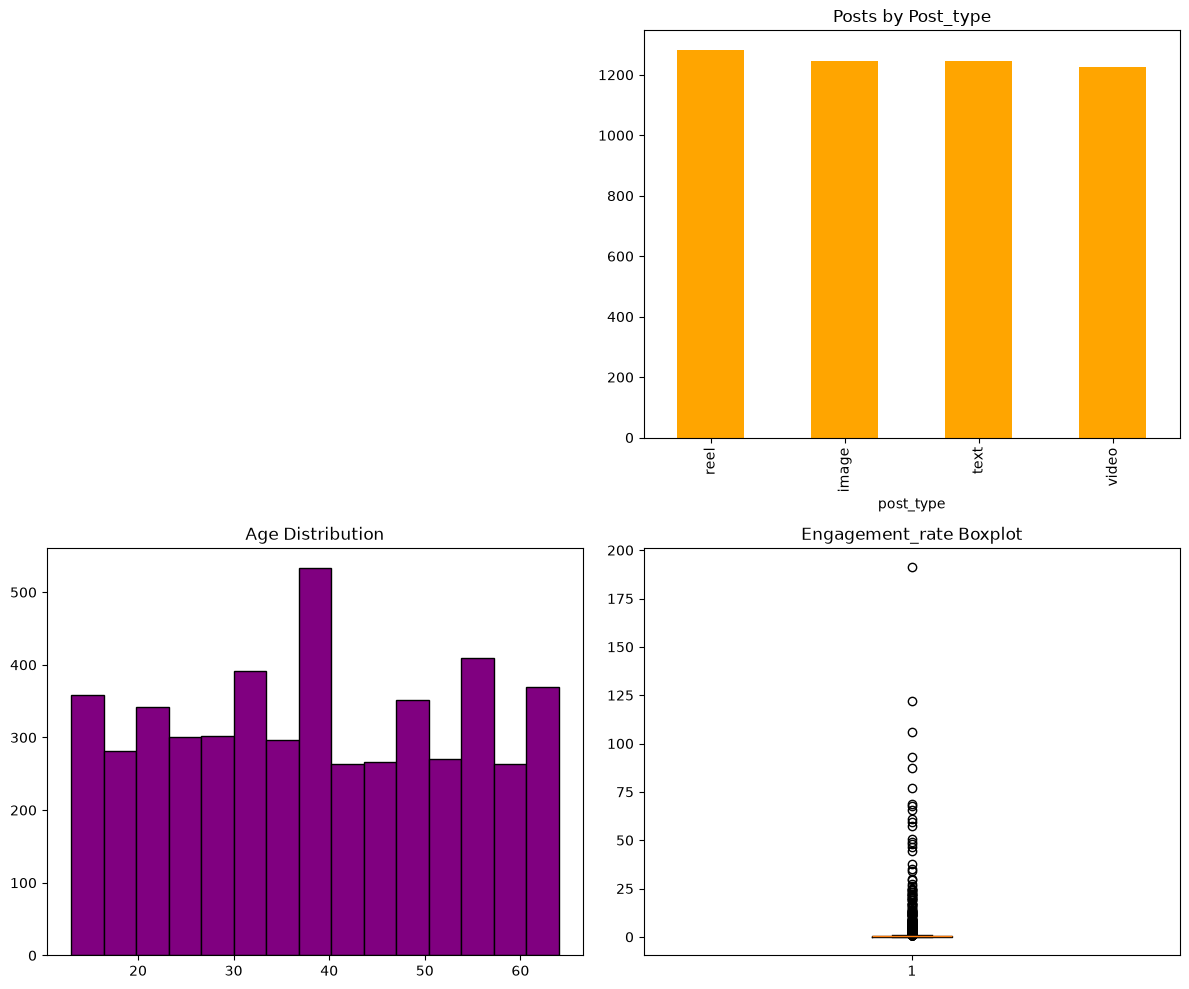

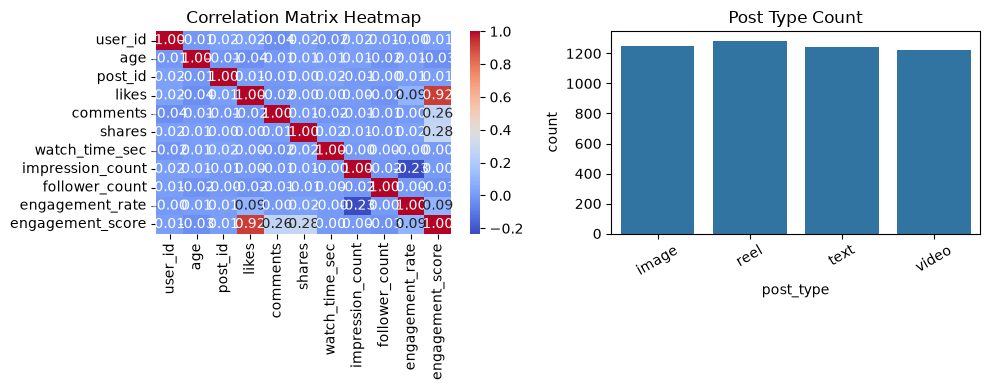

Plotly chart skipped: 'impressions' or 'likes' columns not found.


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 1. Matplotlib Subplots (Safe execution)
plt.figure(figsize=(12, 10))

# Scatter: Likes vs Impressions
if 'impressions' in df.columns and 'likes' in df.columns:
    plt.subplot(2, 2, 1)
    plt.scatter(df['impressions'], df['likes'], alpha=0.5)
    plt.title('Likes vs Impressions')
    plt.xlabel('Impressions')
    plt.ylabel('Likes')

# Bar: Posts by Category (or fallback to post_type)
cat_col = 'category' if 'category' in df.columns else ('post_type' if 'post_type' in df.columns else None)
if cat_col:
    plt.subplot(2, 2, 2)
    df[cat_col].value_counts().plot(kind='bar', color='orange')
    plt.title(f'Posts by {cat_col.capitalize()}')

# Histogram: Age (or fallback to another numeric field)
num_col = 'age' if 'age' in df.columns else ('followers' if 'followers' in df.columns else None)
if num_col:
    plt.subplot(2, 2, 3)
    plt.hist(df[num_col].dropna(), bins=15, color='purple', edgecolor='black')
    plt.title(f'{num_col.capitalize()} Distribution')

# Box Plot: Engagement Rate (or fallback to likes)
box_col = 'engagement_rate' if 'engagement_rate' in df.columns else ('likes' if 'likes' in df.columns else None)
if box_col:
    plt.subplot(2, 2, 4)
    plt.boxplot(df[box_col].dropna())
    plt.title(f'{box_col.capitalize()} Boxplot')

plt.tight_layout()
plt.show()

# 2. Seaborn Heatmap & Countplot
plt.figure(figsize=(10, 4))
numeric_df = df.select_dtypes(include=[np.number])

if not numeric_df.empty:
    plt.subplot(1, 2, 1)
    sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title('Correlation Matrix Heatmap')

if 'post_type' in df.columns:
    plt.subplot(1, 2, 2)
    sns.countplot(data=df, x='post_type')
    plt.title('Post Type Count')
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# 3. Plotly Interactive Chart
if 'impressions' in df.columns and 'likes' in df.columns:
    color_col = 'post_type' if 'post_type' in df.columns else None
    fig = px.scatter(df, x='impressions', y='likes', color=color_col,
                     title="Interactive Impressions vs Likes Analytics")
    fig.show()
else:
    print("Plotly chart skipped: 'impressions' or 'likes' columns not found.")